# 02 — Train SARIMA and compare forecasting methods

We use only the **monthly nursing PPE time series**. No additional predictors enter the models.

To measure predictive performance honestly, we train on January 2016–December 2025 and **withhold January–October 2026**. All methods forecast the same ten months without seeing any of their true values.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
assert (ROOT / "data").exists(), "Run Jupyter from the project root or notebooks/ folder."
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ppe_forecasting import (
    load_monthly_series, chronological_split, naive_forecast,
    seasonal_naive_forecast, moving_average_forecast,
    score_forecast, select_by_train_aic, fit_sarima, TEST_MONTHS
)
y = load_monthly_series(ROOT / "data/processed/nursing_workforce_monthly.csv")
train, test = chronological_split(y, TEST_MONTHS)
print("Train:", train.index.min().date(), "to", train.index.max().date())
print("Test:", test.index.min().date(), "to", test.index.max().date())

Train: 2016-01-31 to 2025-12-31
Test: 2026-01-31 to 2026-10-31


## 1. Three simple methods to beat

- **Last value:** repeat the last known month's PPE.
- **Same month last year:** repeat the corresponding value from the last observed year.
- **Three-month average:** repeat the mean of the last three *observed training* months.

All three predict the full horizon from the training cutoff — no peeking at later actual values.

In [2]:
steps = len(test)
benchmark_predictions = {
    "Last observed value": naive_forecast(train, steps),
    "Same month last year": seasonal_naive_forecast(train, steps),
    "Last 3-month average": moving_average_forecast(train, steps),
}

## 2. Train one seasonal time-series model: SARIMA

A SARIMA model learns from past PPE values and recurring patterns. We try **three small configurations**, choose the one with the lowest **training-period AIC**, and do not select settings based on the test-period errors. This keeps the demonstration readable.

In [3]:
order, seasonal_order, model, candidate_table = select_by_train_aic(train)
display(candidate_table)
print("Chosen SARIMA:", order, "×", seasonal_order)

,order,seasonal_order,AIC_train,converged
0,"(1, 1, 0)","(1, 0, 1, 12)",869.589,True
1,"(0, 1, 1)","(0, 1, 1, 12)",752.655,True
2,"(1, 1, 1)","(1, 0, 0, 12)",872.215,True


Chosen SARIMA: (0, 1, 1) × (0, 1, 1, 12)


## 3. Predict and compare

We compare all four methods using **MAE**, their average absolute error in PPE units (smaller is better). RMSE and MAPE offer additional perspectives. One ten-month test period is only an initial check.

In [4]:
sarima_prediction = model.get_forecast(steps=steps).predicted_mean.to_numpy()
all_predictions = {"SARIMA": sarima_prediction, **benchmark_predictions}
metrics = pd.DataFrame([
    {"method": name, **score_forecast(test.to_numpy(), forecast)}
    for name, forecast in all_predictions.items()
]).sort_values("MAE")
validation = pd.DataFrame({
    "month": test.index,
    "observed_ppe": test.to_numpy(),
    **{f"forecast_{name.lower().replace(' ', '_')}": values for name, values in all_predictions.items()},
})
display(metrics.round(3))
print("Best MAE:", metrics.iloc[0]["method"])

,method,MAE,RMSE,MAPE_pct
0,SARIMA,14.097,16.659,0.904
1,Last observed value,41.816,43.979,2.684
2,Same month last year,43.491,45.978,2.792
3,Last 3-month average,44.576,46.611,2.861


Best MAE: SARIMA


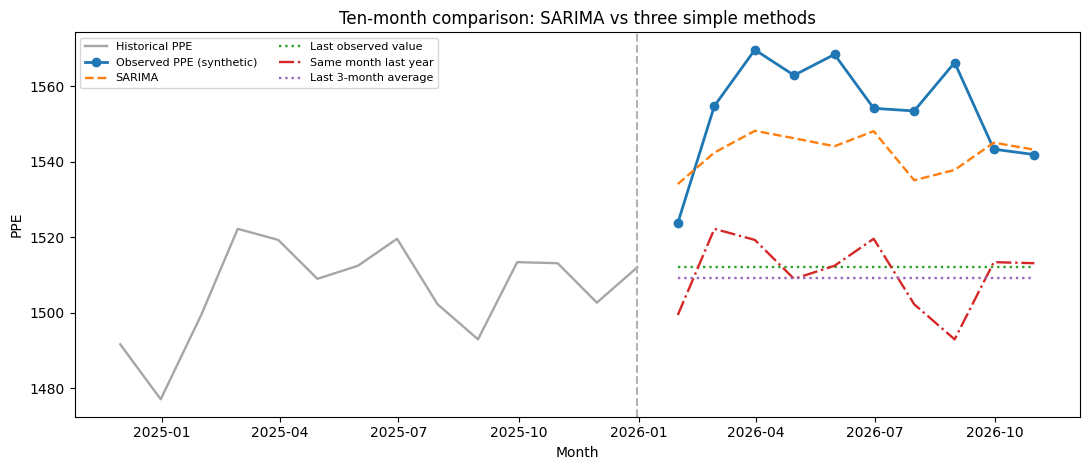

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(train.index[-14:], train.iloc[-14:], label="Historical PPE", color="0.65", linewidth=1.7)
ax.plot(test.index, test, label="Observed PPE (synthetic)", marker="o", linewidth=2)
styles = {"SARIMA": "--", "Last observed value": ":", "Same month last year": "-.", "Last 3-month average": ":"}
for name, values in all_predictions.items():
    ax.plot(test.index, values, styles[name], label=name, linewidth=1.7)
ax.axvline(train.index.max(), linestyle="--", color="0.7")
ax.set(title="Ten-month comparison: SARIMA vs three simple methods", xlabel="Month", ylabel="PPE")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/03_holdout_validation.png", dpi=150)
plt.show()

## 4. Refit SARIMA using every observed month

Having completed the test, refit the selected configuration with all 130 monthly observations to predict November–December 2026. The fitted model is saved **locally only** and should never be loaded from an untrusted source.

In [6]:
full_model = fit_sarima(y, order, seasonal_order)
model_path = ROOT / "outputs/models/nursing_sarima_results.pkl"
model_path.parent.mkdir(parents=True, exist_ok=True)
full_model.save(model_path)
reports = ROOT / "outputs/reports"
reports.mkdir(parents=True, exist_ok=True)
metrics.to_csv(reports / "validation_metrics.csv", index=False, float_format="%.5f")
validation.to_csv(reports / "validation_predictions.csv", index=False, float_format="%.3f")
metadata = {
    "data": "100% synthetic nursing workforce PPE",
    "target": "PPE",
    "model": "univariate SARIMA",
    "order": list(order),
    "seasonal_order": list(seasonal_order),
    "test_months": len(test),
    "training_end": train.index.max().strftime("%Y-%m-%d"),
    "history_end": y.index.max().strftime("%Y-%m-%d"),
    "selection": "Lowest AIC on training data among three SARIMA candidates",
}
(reports / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf8")
print("Saved synthetic validation results and fitted model")

Saved synthetic validation results and fitted model
